# SFT Category Analysis

Analyse Semantic Fluency Test (SFT) transcripts by mapping each spoken animal token to its biological category and visualising the results.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from dataloader import TranscriptLoader

sns.set_theme(style="whitegrid", palette="colorblind")

# Load category lookup from categories.csv
cat_df = pd.read_csv("categories.csv")
category_lookup = dict(zip(cat_df["answer"], cat_df["category"]))
print(f"Loaded {len(category_lookup)} category mappings")
print("Categories:", sorted(cat_df["category"].unique()))

Loaded 406 category mappings
Categories: ['Amphibian', 'Arachnid', 'Bird', 'Fish', 'Insect', 'Invertebrate', 'Mammal', 'Mythical', 'Reptile', 'Unknown/Other']


## Load 10 SFT Transcripts

In [2]:
loader = TranscriptLoader()
all_paths = loader.discover_transcript_files()

sft_paths = [p for p in all_paths if loader.infer_task_from_filename(p.name) == "SFT"]
print(f"Found {len(sft_paths)} SFT transcripts total")

selected_paths = sft_paths[:10]
print(f"Using first {len(selected_paths)} for analysis:")
for p in selected_paths:
    print(f"  {p.parent.name}/{p.name}")

frames = [loader.load_transcript(p) for p in selected_paths]
df = pd.concat(frames, ignore_index=True)

df["token_clean"] = df["token"].str.strip().str.lower()
print(f"\nLoaded {len(df)} tokens across {df['recording'].nunique()} recordings")
df.head(10)

Found 91 SFT transcripts total
Using first 10 for analysis:
  Process-rec-004/Process-rec-004__SFT.txt
  Process-rec-006/Process-rec-006_SFT.txt
  Process-rec-009/Process-rec-009__SFT.txt
  Process-rec-010/Process-rec-010__SFT.txt
  Process-rec-013/Process-rec-013_SFT.txt
  Process-rec-014/Process-rec-014_SFT.txt
  Process-rec-015/Process-rec-015__SFT.txt
  Process-rec-016/Process-rec-016_SFT.txt
  Process-rec-018/Process-rec-018__SFT.txt
  Process-rec-019/Process-rec-019__SFT.txt

Loaded 183 tokens across 10 recordings


,start_time,end_time,token,recording,task,recording_number,source_path,token_clean
0,4.444,5.188,cheetah,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,cheetah
1,5.82,6.692,lion,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,lion
2,7.292,8.388,panda,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,panda
3,9.596,11.076,panda,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,panda
4,14.588,15.448,elephant,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,elephant
5,15.448,16.036,giraffe,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,giraffe
6,17.596,18.34,springbok,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,springbok
7,18.844,19.62,zebra,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,zebra
8,20.284,21.124,rhinoceros,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,rhinoceros
9,24.764,25.796,armadillo,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,armadillo


## Map Tokens to Categories

In [3]:
df["category"] = df["token_clean"].map(category_lookup).fillna("Unknown/Other")

unmatched = df.loc[df["category"] == "Unknown/Other", "token_clean"].unique()
print(f"Matched: {(df['category'] != 'Unknown/Other').sum()} / {len(df)} tokens")
if len(unmatched):
    print(f"Unmatched tokens ({len(unmatched)}): {list(unmatched[:20])}")

df[["recording", "start_time", "token_clean", "category"]].head(15)

Matched: 178 / 183 tokens
Unmatched tokens (2): ['?', 'jack']


,recording,start_time,token_clean,category
0,Process-rec-004,4.444,cheetah,Mammal
1,Process-rec-004,5.82,lion,Mammal
2,Process-rec-004,7.292,panda,Mammal
3,Process-rec-004,9.596,panda,Mammal
4,Process-rec-004,14.588,elephant,Mammal
5,Process-rec-004,15.448,giraffe,Mammal
6,Process-rec-004,17.596,springbok,Mammal
7,Process-rec-004,18.844,zebra,Mammal
8,Process-rec-004,20.284,rhinoceros,Mammal
9,Process-rec-004,24.764,armadillo,Mammal


## 1. Bar Chart — Category Distribution (All Recordings)

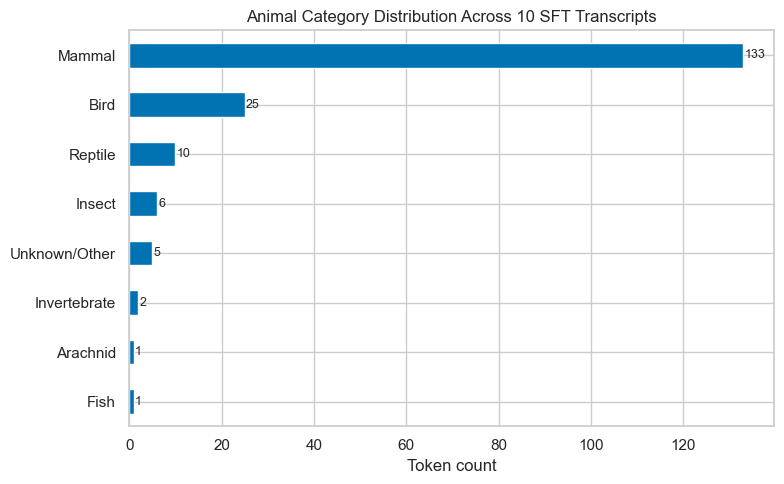

In [4]:
cat_counts = df["category"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
cat_counts.plot.barh(ax=ax)
ax.set_xlabel("Token count")
ax.set_ylabel("")
ax.set_title("Animal Category Distribution Across 10 SFT Transcripts")
for i, v in enumerate(cat_counts):
    ax.text(v + 0.3, i, str(v), va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 2. Stacked Bar Chart — Categories per Recording

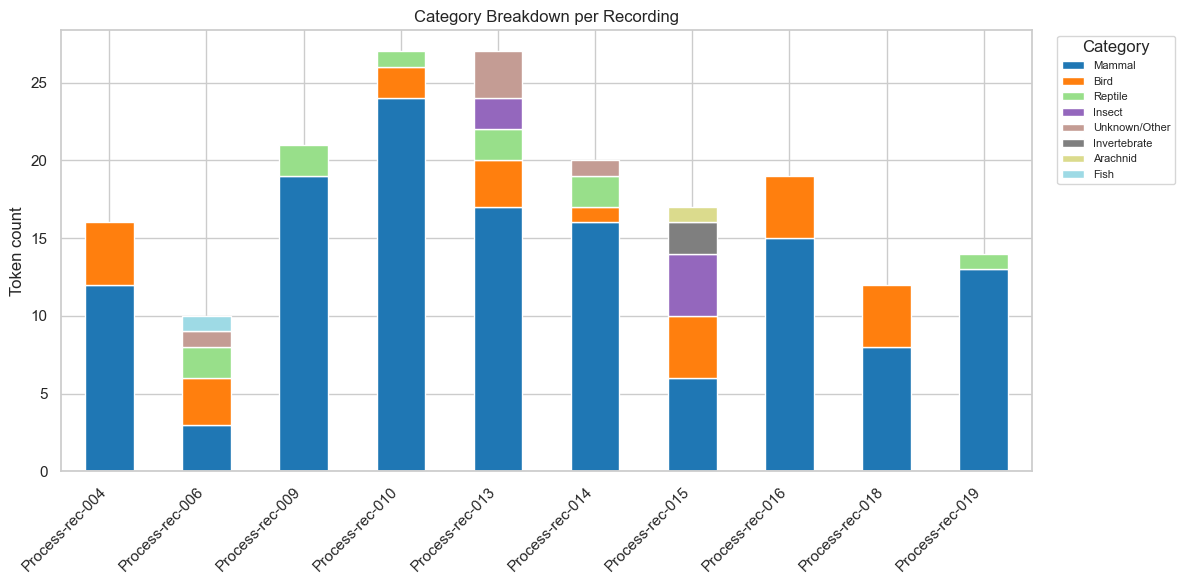

In [5]:
cross = pd.crosstab(df["recording"], df["category"])
cross = cross[cat_counts.index[::-1]]  # order columns by overall frequency

fig, ax = plt.subplots(figsize=(12, 6))
cross.plot.bar(stacked=True, ax=ax, colormap="tab20")
ax.set_ylabel("Token count")
ax.set_xlabel("")
ax.set_title("Category Breakdown per Recording")
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 3. Category Proportion Heatmap

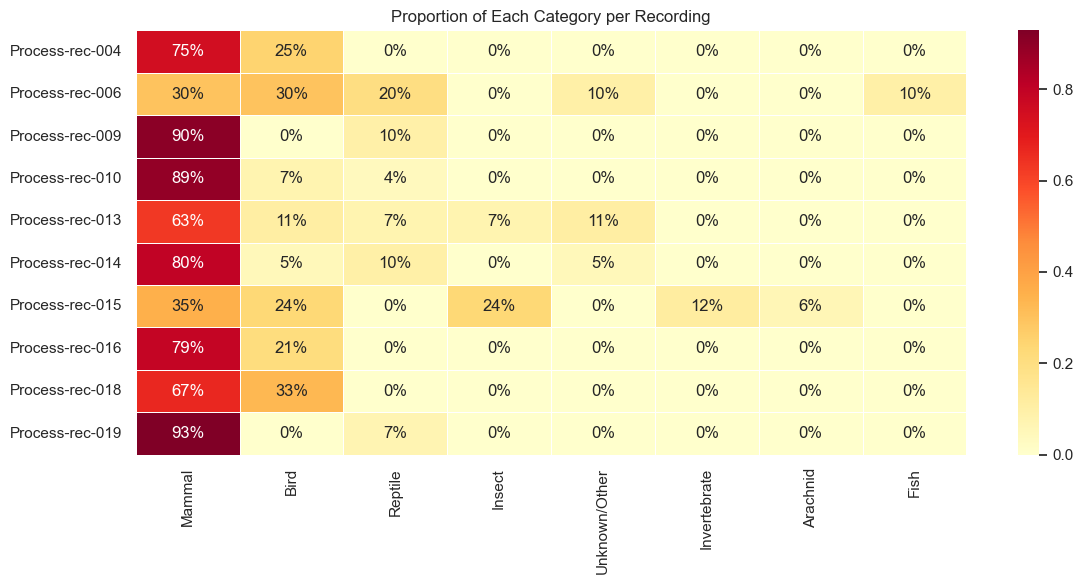

In [6]:
proportions = cross.div(cross.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    proportions,
    annot=True,
    fmt=".0%",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Proportion of Each Category per Recording")
ax.set_ylabel("")
ax.set_xlabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Temporal Category Sequence (Single Recording)

Each dot represents a token placed at its `start_time`, coloured by category. Clusters of the same colour reveal semantic grouping; colour changes indicate category switches.

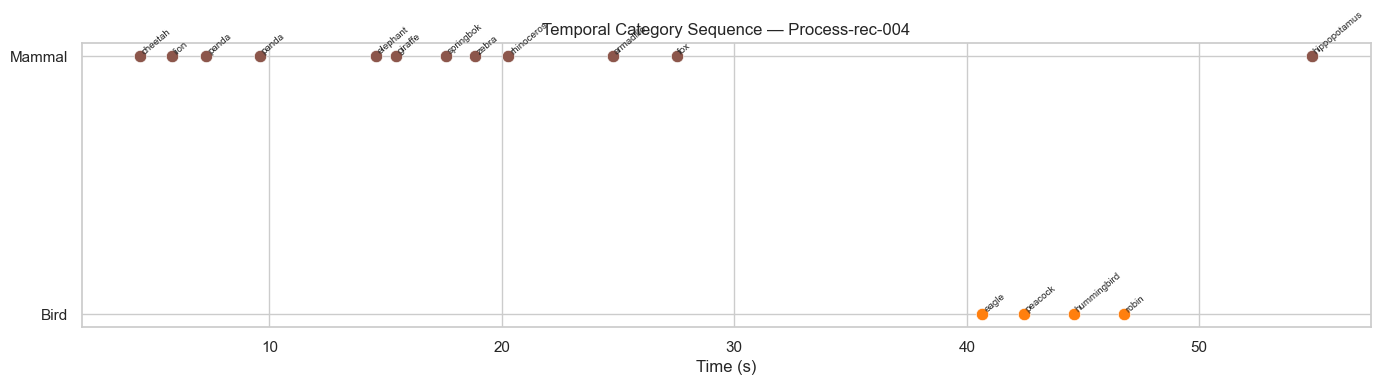

In [7]:
sample_recording = df["recording"].unique()[0]
sample = df[df["recording"] == sample_recording].copy()
sample = sample.sort_values("start_time").reset_index(drop=True)

all_cats = sorted(df["category"].unique())
palette = dict(zip(all_cats, sns.color_palette("tab10", len(all_cats))))

fig, ax = plt.subplots(figsize=(14, 4))
for cat in all_cats:
    mask = sample["category"] == cat
    ax.scatter(
        sample.loc[mask, "start_time"],
        [cat] * mask.sum(),
        color=palette[cat],
        s=80,
        label=cat,
        edgecolors="white",
        linewidth=0.5,
        zorder=3,
    )

for _, row in sample.iterrows():
    ax.annotate(
        row["token_clean"],
        (row["start_time"], row["category"]),
        fontsize=7,
        rotation=40,
        ha="left",
        va="bottom",
    )

ax.set_xlabel("Time (s)")
ax.set_title(f"Temporal Category Sequence — {sample_recording}")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 5. Category Switching Analysis

A *switch* occurs when consecutive tokens belong to different categories. Higher switch rates may reflect stronger executive function and flexible retrieval strategies.

/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_81894/3135207499.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  switch_df = df.groupby("recording").apply(compute_switch_rate).reset_index()


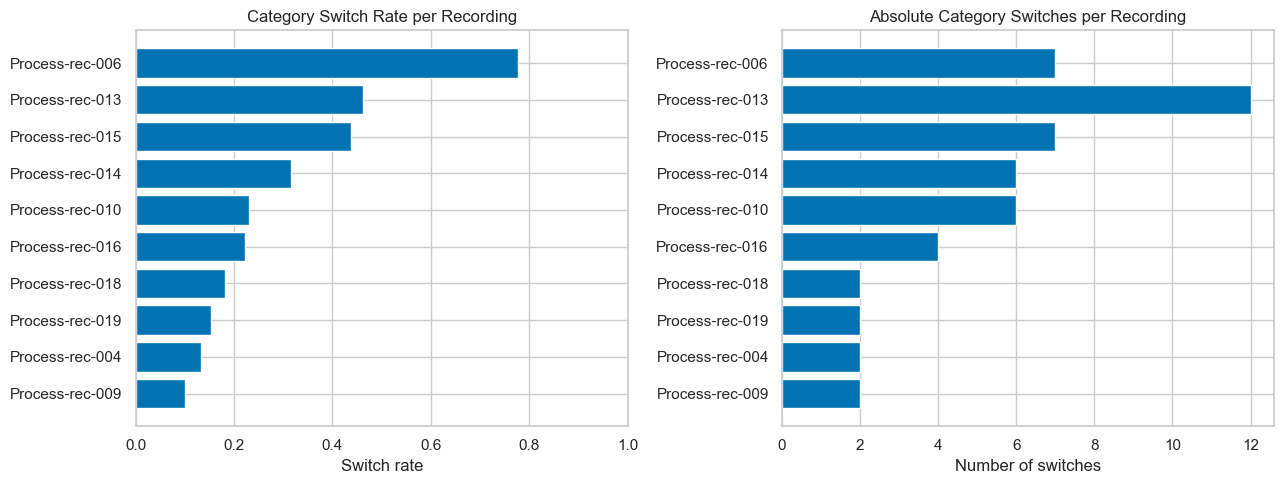

Mean switch rate: 30.15%


,recording,switches,total_transitions,switch_rate
0,Process-rec-004,2.0,15.0,0.133333
1,Process-rec-006,7.0,9.0,0.777778
2,Process-rec-009,2.0,20.0,0.100000
3,Process-rec-010,6.0,26.0,0.230769
4,Process-rec-013,12.0,26.0,0.461538
5,Process-rec-014,6.0,19.0,0.315789
6,Process-rec-015,7.0,16.0,0.437500
7,Process-rec-016,4.0,18.0,0.222222
8,Process-rec-018,2.0,11.0,0.181818
9,Process-rec-019,2.0,13.0,0.153846


In [8]:
def compute_switch_rate(group):
    group = group.sort_values("start_time")
    cats = group["category"].values
    if len(cats) < 2:
        return pd.Series({"switches": 0, "total_transitions": 0, "switch_rate": np.nan})
    switches = sum(a != b for a, b in zip(cats[:-1], cats[1:]))
    total = len(cats) - 1
    return pd.Series({"switches": switches, "total_transitions": total, "switch_rate": switches / total})

switch_df = df.groupby("recording").apply(compute_switch_rate).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

switch_df_sorted = switch_df.sort_values("switch_rate", ascending=True)
axes[0].barh(switch_df_sorted["recording"], switch_df_sorted["switch_rate"])
axes[0].set_xlabel("Switch rate")
axes[0].set_title("Category Switch Rate per Recording")
axes[0].set_xlim(0, 1)

axes[1].barh(switch_df_sorted["recording"], switch_df_sorted["switches"])
axes[1].set_xlabel("Number of switches")
axes[1].set_title("Absolute Category Switches per Recording")

plt.tight_layout()
plt.show()

print(f"Mean switch rate: {switch_df['switch_rate'].mean():.2%}")
switch_df

## 6. Pie Chart — Overall Category Proportions

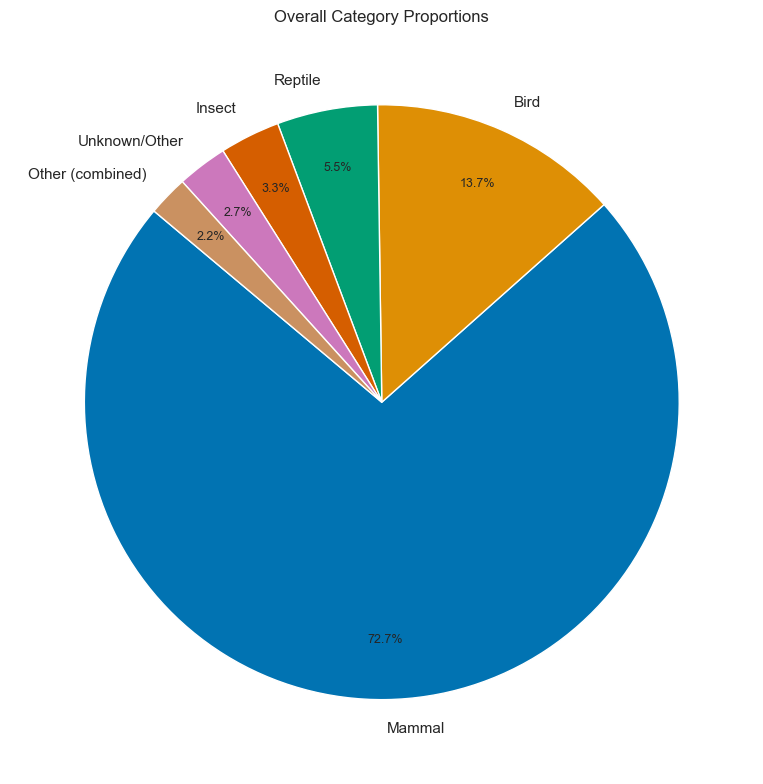

In [9]:
cat_totals = df["category"].value_counts()

threshold = 0.02 * len(df)
main_cats = cat_totals[cat_totals >= threshold]
other_sum = cat_totals[cat_totals < threshold].sum()
if other_sum > 0:
    main_cats["Other (combined)"] = other_sum

fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    main_cats,
    labels=main_cats.index,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.8,
)
for t in autotexts:
    t.set_fontsize(9)
ax.set_title("Overall Category Proportions")
plt.tight_layout()
plt.show()